# Early Crop Yield Estimation for Indian Districts

**The problem.** More than half of India's workforce depends on agriculture, and a bad season can wipe out a farmer's income. Crop insurance payouts, drought relief and procurement planning all depend on **official yield estimates**, which arrive months after the harvest. Farmers wait, and decisions are made late.

**The question.** Can we estimate a district's crop yield **early**, using only:
1. the district's own yield history, and
2. yields **already reported by other districts in the same state** that season?

**Data.** Crop-wise Area, Production and Yield statistics for every Indian district, 1997–2014, published by the Ministry of Agriculture on data.gov.in (about 246,000 records). I pay special attention to **Dharwad, Karnataka**, my home district.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, precision_score, recall_score
from sklearn.inspection import permutation_importance
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
raw = pd.read_csv("data/crop_production.csv")
print(raw.shape); raw.head()

(246091, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


## 1. Cleaning

- Strip extra spaces from season names.
- Keep **17 major crops** measured in tonnes (cotton, jute and coconut use different units, so they are excluded).
- Drop rows with missing production, zero production, or tiny areas (< 10 ha), which give unreliable yields.
- Drop 2015, which has only a few hundred records.
- Compute **yield = production / area** (tonnes per hectare) and remove the top 0.5% of yields per crop as data-entry errors.

In [2]:
CROPS = ["Rice","Wheat","Maize","Jowar","Bajra","Ragi","Arhar/Tur","Moong(Green Gram)","Urad","Gram",
         "Groundnut","Sunflower","Soyabean","Rapeseed &Mustard","Sugarcane","Potato","Onion"]
d = raw.copy()
d["Season"] = d["Season"].str.strip()
d = d[d.Crop.isin(CROPS) & d.Production.notna() & (d.Production > 0) & (d.Area >= 10) & (d.Crop_Year <= 2014)]
d["Yield"] = d.Production / d.Area
d = d[d.Yield <= d.groupby("Crop").Yield.transform(lambda s: s.quantile(0.995))]
KEY = ["State_Name","District_Name","Crop","Season"]
d = d.groupby(KEY + ["Crop_Year"], as_index=False).agg(Area=("Area","sum"), Production=("Production","sum"))
d["Yield"] = d.Production / d.Area
print(f"{len(raw):,} raw rows -> {len(d):,} clean rows, {d.District_Name.nunique()} districts, {d.State_Name.nunique()} states")

246,091 raw rows -> 125,374 clean rows, 645 districts, 33 states


## 2. Exploring the data

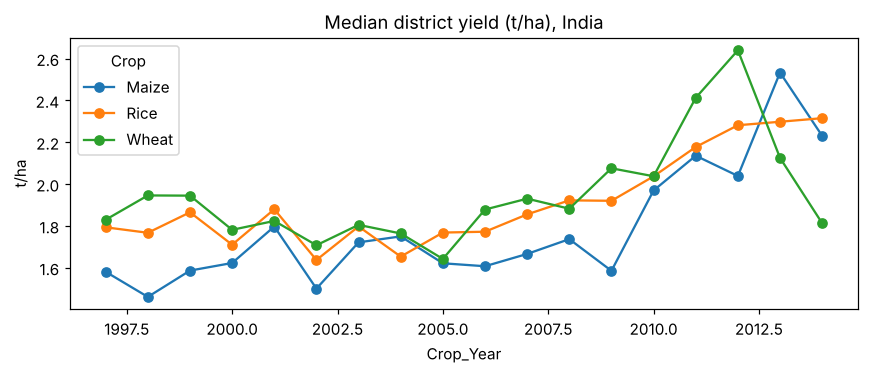

In [3]:
trend = d[d.Crop.isin(["Rice","Wheat","Maize"])].groupby(["Crop_Year","Crop"]).Yield.median().unstack()
trend.plot(figsize=(8,3.5), marker="o", title="Median district yield (t/ha), India")
plt.ylabel("t/ha"); plt.tight_layout(); plt.savefig("images/national_trend.png"); plt.show()

Yields rise slowly over time, but individual years still swing up and down, mostly because of the monsoon.

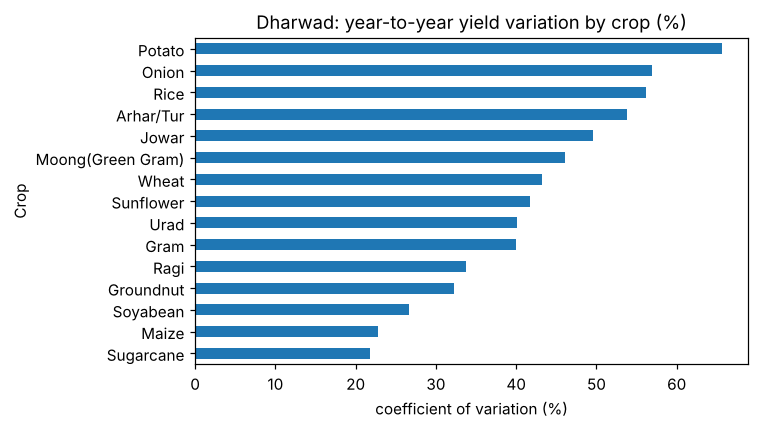

,mean,std,count,variation %
Crop,,,,
Sugarcane,67.57,14.74,16,21.8
Maize,2.60,0.59,54,22.8
Soyabean,0.73,0.19,17,26.7
Groundnut,0.90,0.29,35,32.2
Ragi,1.12,0.38,19,33.7
Gram,0.51,0.20,19,40.0
Urad,0.29,0.12,16,40.1
Sunflower,0.51,0.21,43,41.7
Wheat,0.65,0.28,18,43.2


In [4]:
dw = d[d.District_Name == "DHARWAD"]
vol = (dw.groupby("Crop").Yield.agg(["mean","std","count"]).query("count >= 10"))
vol["variation %"] = (vol["std"] / vol["mean"] * 100).round(1)
vol = vol.sort_values("variation %")
vol["variation %"].plot.barh(figsize=(7,4), title="Dharwad: year-to-year yield variation by crop (%)")
plt.xlabel("coefficient of variation (%)"); plt.tight_layout(); plt.savefig("images/dharwad_risk.png"); plt.show()
vol.round(2)

Higher variation means a riskier crop for a Dharwad farmer: the same field can give a very different harvest from one year to the next.

## 3. Features (without cheating)

For each district, crop and season in year *t*, I use only information that would be available **before** the district's own official figure:

| Feature | Meaning |
|---|---|
| `lag1`, `lag2` | the district's yield 1 and 2 years earlier |
| `hist_mean` | the district's average yield over all previous years |
| `peer_mean` | average yield **this year** of the *other* districts in the same state (same crop and season) |
| `peer_ratio` | how the other districts did this year **compared with their own history** (e.g. 0.8 = 20% worse than usual) |
| `log_area`, `Crop`, `Season`, `State_Name`, `Crop_Year` | context |

`peer_ratio` captures shared shocks such as a weak monsoon across the state. The district's own yield is always excluded from these averages.

In [5]:
d = d.sort_values("Crop_Year")
g = d.groupby(KEY)
d["lag1"] = g.Yield.shift(1)
d["lag2"] = g.Yield.shift(2)
d["hist_mean"] = g.Yield.transform(lambda s: s.shift(1).expanding().mean())
d = d[d.lag2.notna()].copy()

PEER = ["State_Name","Crop","Season","Crop_Year"]
n = d.groupby(PEER).Yield.transform("count")
d["peer_mean"] = (d.groupby(PEER).Yield.transform("sum") - d.Yield) / (n - 1)
d["ratio"] = d.Yield / d.hist_mean
d["peer_ratio"] = (d.groupby(PEER).ratio.transform("sum") - d.ratio) / (n - 1)
d = d[n >= 4].copy()            # need at least 3 other districts reporting
d["log_area"] = np.log1p(d.Area)
for c in ["State_Name","Crop","Season"]:
    d[c] = d[c].astype("category")
FEATS = ["State_Name","Crop","Season","Crop_Year","log_area","lag1","lag2","hist_mean","peer_mean","peer_ratio"]
print(f"{len(d):,} rows ready for modelling")

98,649 rows ready for modelling


## 4. Model and honest evaluation

I split by **time**, not randomly: train on 1999–2010 and test on **2011–2014**, years the model has never seen. This mimics real use.

The model is a **gradient-boosted tree regressor**. It predicts the ratio *this year's yield / historical average* (in log scale), which puts all crops on the same footing.

I compare it with three simple baselines a government officer could use without ML.

In [6]:
train = d[d.Crop_Year <= 2010]; test = d[d.Crop_Year >= 2011].copy()
model = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=500,
                                      learning_rate=0.05, random_state=RANDOM_STATE)
model.fit(train[FEATS], np.log(train.Yield / train.hist_mean))
test["model"] = np.exp(model.predict(test[FEATS])) * test.hist_mean
test["last_year"] = test.lag1
test["history_avg"] = test.hist_mean
test["history_x_peers"] = test.hist_mean * test.peer_ratio

def med_ape(a, p): return np.median(np.abs(p - a) / a) * 100
rows = []
for name in ["last_year","history_avg","history_x_peers","model"]:
    rows.append({"method": name,
                 "median % error": med_ape(test.Yield, test[name]),
                 "MAE (t/ha)": mean_absolute_error(test.Yield, test[name]),
                 "R²": r2_score(test.Yield, test[name])})
results = pd.DataFrame(rows).set_index("method").round(3)
print(f"Train: {len(train):,} rows | Test: {len(test):,} rows")
results

Train: 74,202 rows | Test: 24,447 rows


,median % error,MAE (t/ha),R²
method,,,
last_year,13.846,1.040,0.924
history_avg,18.559,1.170,0.923
history_x_peers,11.767,0.797,0.962
model,11.221,0.810,0.956


In [7]:
dh = test[test.District_Name == "DHARWAD"]
print(f"Dharwad test cases: {len(dh)}")
print(f"  median error, last year's yield: {med_ape(dh.Yield, dh.last_year):.1f}%")
print(f"  median error, model:             {med_ape(dh.Yield, dh.model):.1f}%")

Dharwad test cases: 94
  median error, last year's yield: 22.8%
  median error, model:             11.9%


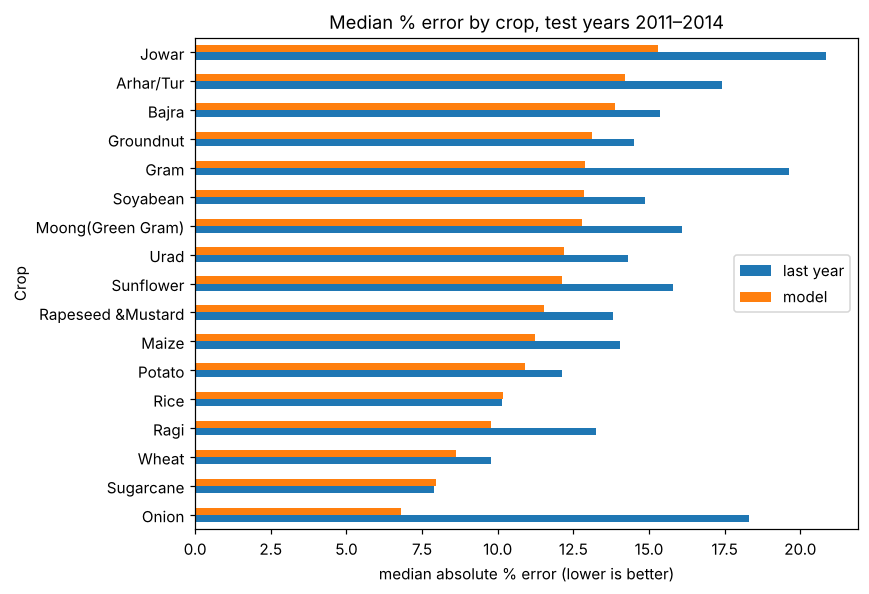

In [8]:
by_crop = test.groupby("Crop", observed=True).apply(
    lambda s: pd.Series({"last year": med_ape(s.Yield, s.last_year), "model": med_ape(s.Yield, s.model)}),
    include_groups=False).sort_values("model")
by_crop.plot.barh(figsize=(8,5.5), title="Median % error by crop, test years 2011–2014")
plt.xlabel("median absolute % error (lower is better)"); plt.tight_layout(); plt.savefig("images/error_by_crop.png"); plt.show()

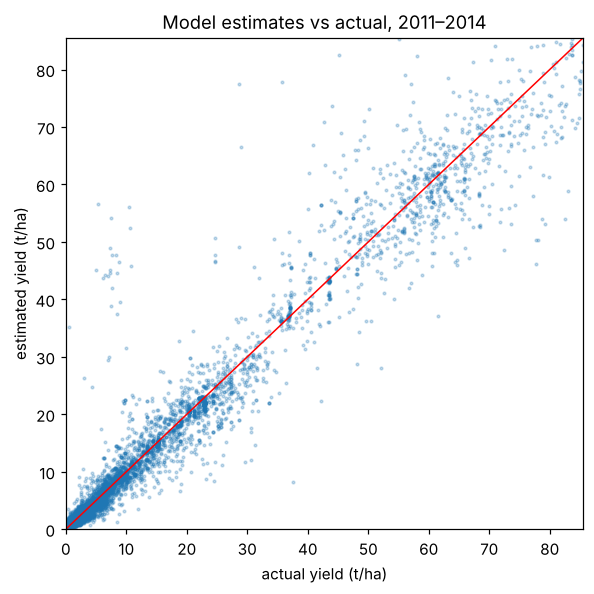

In [9]:
fig, ax = plt.subplots(figsize=(5.5,5.5))
ax.scatter(test.Yield, test.model, s=3, alpha=0.25)
lim = np.percentile(test.Yield, 99)
ax.plot([0,lim],[0,lim], color="red", lw=1)
ax.set_xlim(0,lim); ax.set_ylim(0,lim)
ax.set_xlabel("actual yield (t/ha)"); ax.set_ylabel("estimated yield (t/ha)")
ax.set_title("Model estimates vs actual, 2011–2014")
plt.tight_layout(); plt.savefig("images/pred_vs_actual.png"); plt.show()

## 5. What drives the estimate?

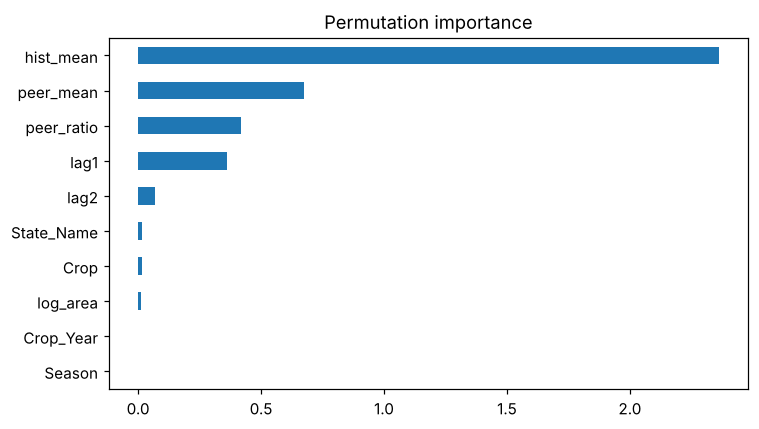

In [10]:
sample = test.sample(4000, random_state=RANDOM_STATE)
pi = permutation_importance(model, sample[FEATS], np.log(sample.Yield / sample.hist_mean),
                            n_repeats=5, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
imp.plot.barh(figsize=(7,4), title="Permutation importance")
plt.tight_layout(); plt.savefig("images/feature_importance.png"); plt.show()

## 6. Early warning: spotting crop failures

I define a **crop failure** as a yield below **70%** of the district's historical average. Can the model flag these early?

The alert threshold is chosen on **validation years 2009–2010** (not on the test years), then applied to 2011–2014.

In [11]:
val = d[d.Crop_Year.between(2009, 2010)].copy()
fit = d[d.Crop_Year <= 2008]
m2 = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=500,
                                   learning_rate=0.05, random_state=RANDOM_STATE)
m2.fit(fit[FEATS], np.log(fit.Yield / fit.hist_mean))
val_ratio = np.exp(m2.predict(val[FEATS])); val_fail = val.Yield < 0.7 * val.hist_mean
best = max(np.arange(0.70, 0.96, 0.01),
           key=lambda t: 2*precision_score(val_fail, val_ratio < t)*recall_score(val_fail, val_ratio < t) /
                         (precision_score(val_fail, val_ratio < t) + recall_score(val_fail, val_ratio < t) + 1e-9))
print(f"Alert when the estimate is below {best:.2f} x historical average")

fail = test.Yield < 0.7 * test.hist_mean
for name, est in [("last year's yield", test.last_year), ("model", test.model)]:
    alert = est < best * test.hist_mean
    print(f"{name:18s} precision {precision_score(fail, alert):.2f}  recall {recall_score(fail, alert):.2f}")
print(f"Failure rate in test years: {fail.mean():.1%}")

Alert when the estimate is below 0.83 x historical average
last year's yield  precision 0.20  recall 0.31
model              precision 0.50  recall 0.38
Failure rate in test years: 7.3%


## 7. Conclusions

- Using **same-season reports from neighbouring districts** clearly improves early estimates: the median error falls from **13.8%** (reusing last year's yield) to **11.2%**, and R² rises from 0.92 to 0.96. Bad seasons (weak monsoon, pests) tend to hit a whole state at once.
- An honest finding: the simple rule *history × peer ratio* is almost as good as the ML model (11.8% median error, and even a slightly lower MAE). **The key insight is the peer signal itself**; the gradient-boosted model adds only a small further gain.
- The improvement is largest where weather swings are strongest. In **Dharwad**, the median error roughly **halves** (22.8% → 11.9%).
- Crop-failure alerts improve too (precision 0.20 → 0.50, recall 0.31 → 0.38), but many failures are still missed: some are local (a hailstorm, a pest outbreak in one taluk) and cannot be seen in other districts' data.

**Limitations.** The model needs at least three other districts to have reported; it has no weather, soil or satellite data; and district-level averages hide differences between individual farms.

**Next steps.** Add IMD rainfall and temperature, satellite vegetation indices (NDVI) for in-season signals, and test the approach at taluk level.